# Reinforcement Learning 

Trabalho realizado por:
- Francisco Lopes nº111358
- Raul Azevedo nº111479

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

## Exercício 1

### Alínea a - Função de transição de estados

A função `transition` recebe um estado `s` (de 1 a 100) e uma ação `a`.

 Esta devolve o estado de chegada, sendo que quando o robô movimenta-se para uma parede, este permanece no mesmo estado.

In [47]:
def transition(s, a):
    if a == 'up':
        return s - 10 if s > 10 else s
    elif a == 'down':
        return s + 10 if s <= 90 else s
    elif a == 'left':
        return s - 1 if (s - 1) % 10 != 0 else s
    elif a == 'right':
        return s + 1 if s % 10 != 0 else s
    else:
        raise ValueError(f'Invalid action: {a}')

### Alínea b - Função reward

A função `reward` recebe um estado `s` e devolve a recompensa associada.

Todos os estados têm recompensa 0, exceto o estado final (estado 100) que tem recompensa 100.

In [48]:
def reward(s):
    return 100 if s == 100 else 0

### Alínea c - Escolher aleatoriamente uma ação

A função `random_action` devolve aleatoriamente uma das quatro ações possíveis (up, down, left, right).

In [49]:
ACTIONS = ['up', 'down', 'left', 'right']

def random_action(rng):
    return ACTIONS[rng.integers(len(ACTIONS))]

### Alínea d - Fim de episódio

A função `run_episode` simula um episódio: o robô parte do estado 1 e executa ações aleatórias, registando a recompensa acumulada. O episódio termina em duas situações:

- **Objetivo atingido:** quando o robô chega ao estado 100, recebe a recompensa de 100 pontos e o episódio termina, ficando o robô de novo na posição inicial no episódio seguinte.
- **Limite de passos:** quando o robô executa 1000 ações sem chegar ao objetivo, o episódio termina sem recompensa e o robô regressa à posição inicial.

In [50]:
INITIAL_STATE = 1
GOAL_STATE = 100
MAX_STEPS = 1000

def run_episode(rng, max_steps=MAX_STEPS):
    s = INITIAL_STATE
    total_reward = 0
    for step in range(1, max_steps + 1):
        a = random_action(rng)
        s = transition(s, a)
        total_reward += reward(s)
        if s == GOAL_STATE:
            return step, total_reward, True
    return max_steps, total_reward, False

### Alínea e - Simulação de 30 episódios

A função `run_experiment` repete o episódio da alínea anterior 30 vezes. Em cada repetição registam-se o número de passos, a recompensa média por passo (recompensa total a dividir pelo número de passos), o tempo de execução e o indicador de sucesso.

 A média e o desvio-padrão de cada grandeza são calculados pela função `metrics`.

In [51]:
def run_experiment(n_episodes = 30, seeds=None, episode_fn = run_episode):
    if seeds is None:
        seeds = list(range(n_episodes))

    results = {"seeds": seeds, "steps": [], "reward_per_step": [], "execution_time": [], "success": []}

    for seed in seeds:
        rng = np.random.default_rng(seed)
        start_time = time.perf_counter()
        steps, total_reward, success = episode_fn(rng)
        elapsed_time = time.perf_counter() - start_time

        results["steps"].append(steps)
        results["reward_per_step"].append(total_reward / steps)
        results["execution_time"].append(elapsed_time)
        results["success"].append(success)

    return results

def metrics(results):
     return {metric: (np.mean(results[metric]), np.std(results[metric])) for metric in ("steps", "reward_per_step", "execution_time")}

In [52]:
random_results = run_experiment(n_episodes=30)
baseline = metrics(random_results)

print(f"Episódios com sucesso: {sum(random_results['success'])}/30")
for nome, (media, desvio) in baseline.items():
    print(f"{nome:16s} média = {media:.5f} | desvio-padrão = {desvio:.5f}")

Episódios com sucesso: 22/30
steps            média = 574.00000 | desvio-padrão = 357.96741
reward_per_step  média = 0.31237 | desvio-padrão = 0.33607
execution_time   média = 0.00082 | desvio-padrão = 0.00052


### Alínea f - Boxplots dos resultados

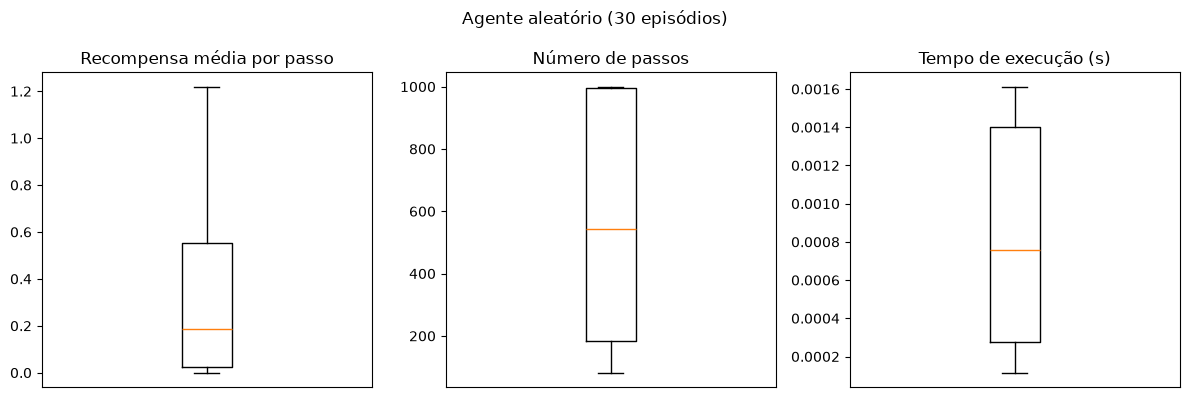

In [53]:
def plot_boxplots(results, title=None):
    metricas = [
        ("reward_per_step", "Recompensa média por passo"),
        ("steps",           "Número de passos"),
        ("execution_time",  "Tempo de execução (s)"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (chave, rotulo) in zip(axes, metricas):
        ax.boxplot(results[chave], orientation="vertical")
        ax.set_title(rotulo)
        ax.set_xticks([])
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_boxplots(random_results, title="Agente aleatório (30 episódios)")

**Resultados e Observações - Agente aleatório**

O agente aleatório atingiu o objetivo em 22 dos 30 episódios (73%). Nos restantes 8, o episódio terminou ao fim de 1000 passos sem recompensa. 

| Grandeza | Média | Desvio-padrão |
|---|---|---|
| Número de passos | 574,00 | 357,97 |
| Recompensa média por passo | 0,312 | 0,336 |

- **Número de passos:** a mediana fica abaixo do limite de 1000 passos, o que significa que mais de metade dos episódios chegou ao objetivo. A dispersão é grande: alguns episódios chegam em poucas dezenas de passos, outros esgotam os 1000 passos sem chegar ao estado 100.
- **Recompensa média por passo:** a mediana está próxima de 0 e muito inferior ao máximo possível, pois mesmo os episódios bem-sucedidos demoram muitos passos a chegar ao objetivo. Os valores mais altos correspondem a episódios em que o objetivo foi atingido rapidamente, e os episódios sem sucesso têm recompensa 0.
- **Tempo de execução:** é proporcional ao número de passos, por isso os episódios que esgotam os 1000 passos são também os mais demorados.

## Exercício 2

In [54]:
ALPHA, GAMMA = 0.7, 0.99
N_STATES = 100
N_TRAIN_STEPS = 20000
TEST_STEPS = 1000
TEST_POINTS = [100, 200, 500, 600, 700, 800, 900, 1000,
               2500, 5000, 7500, 10000, 12500, 15000, 17500, 20000]

A função `random_policy` é a política usada no random walk: ignora a tabela Q e devolve uma ação escolhida ao acaso. Tem a mesma assinatura que `best_action`, o que permite trocar a política de treino sem alterar o resto do código - politica usada na alínea a

A função `best_action` devolve a ação com maior valor Q nesse estado. Quando várias ações têm o mesmo valor máximo (por exemplo, no início, com Q toda a zeros), o empate é desfeito ao acaso - politica usada na alínea b

A função `update_q` atualiza a entrada Q[s, a], a partir do estado de partida `s`, da ação `a` e do estado de chegada `s'`, com alpha = 0.7 e gamma = 0.99. A atualização combina o valor anterior com a recompensa recebida em `s'` e o melhor valor Q disponível a partir de `s'`.

A função `test_policy` avalia a política aprendida: o robô executa 1000 passos a partir do estado inicial, escolhendo sempre a melhor ação segundo Q, sem modificar a tabela. Sempre que atinge o objetivo, regressa ao estado inicial. A função devolve a recompensa média por passo nesses 1000 passos.

Na função `run_q_learning`:

- é realizada uma experiência completa de treino com uma respetiva seed: inicializa Q com zeros, treina durante 20 000 passos com a política indicada e, nos pontos definidos em `TEST_POINTS`, interrompe o treino para correr `test_policy`. 
- o robô regressa ao estado inicial ao atingir o objetivo ou ao fim de 1000 passos, e a atualização de Q é feita antes desse regresso.
- o treino e os testes usam geradores aleatórios distintos, derivados da mesma seed, para que os testes não alterem a sequência de ações do treino. 
- a função devolve as recompensas dos testes, o tempo de execução total e a tabela Q final.

In [55]:
# politica da alinea a)
def random_policy(Q, s, rng, step=None):
    return random_action(rng) # escolhe uma ação aleatória, ignorando Q

# politica da alinea b)
def best_action(Q, s, rng, step=None):
    q = Q[s - 1] # Valores Q para o estado s
    return ACTIONS[rng.choice(np.flatnonzero(q == q.max()))]

def update_q(Q, s, a, s_next):
    i = ACTIONS.index(a)
    Q[s - 1, i] = (1- ALPHA) * Q[s - 1, i] + ALPHA * (reward(s_next) + GAMMA * Q[s_next - 1].max())

def test_policy(Q, rng, n_steps=TEST_STEPS):
    s = INITIAL_STATE
    total_reward = 0
    for _ in range(n_steps):
        s = transition(s, best_action(Q, s, rng)) # escolhe sempre a melhor ação segundo Q
        total_reward += reward(s)
        if s == GOAL_STATE:
            s = INITIAL_STATE
    return total_reward / n_steps

def run_q_learning(seed, train_policy=random_policy, n_steps=N_TRAIN_STEPS, test_points=TEST_POINTS):
    rng_train = np.random.default_rng(seed)
    rng_test = np.random.default_rng(seed + 10000)
    Q = np.zeros((N_STATES, len(ACTIONS)))

    s = INITIAL_STATE
    episode_steps = 0
    test_rewards = []
    q_snapshots = {}

    start_time = time.perf_counter()
    for step in range(1, n_steps + 1):
        a = train_policy(Q, s, rng_train, step) # escolhe uma ação segundo a política de treinamento
        s_next = transition(s, a) # determina o próximo estado
        update_q(Q, s, a, s_next) # atualiza a tabela Q
        episode_steps += 1

        if s_next == GOAL_STATE or episode_steps == MAX_STEPS:
            s_next = INITIAL_STATE
            episode_steps = 0

        s = s_next
        # Avalia a política de teste em pontos específicos durante o treinamento, sem alterar a tabela Q
        if step in test_points:
            test_rewards.append(test_policy(Q, rng_test))
            q_snapshots[step] = Q.copy()

    elapsed_time = time.perf_counter() - start_time
    return {"test_rewards": test_rewards, "execution_time": elapsed_time, "Q": Q, "q_snapshots": q_snapshots}


### Alínea a - Q-learning com random walk

In [56]:
def run_experiments(n_experiments=30, train_policy=random_policy):
    results = []

    for seed in range(n_experiments):
        result = run_q_learning(seed, train_policy=train_policy)
        result["seed"] = seed
        results.append(result)

    return results

def analyze_results(results):
    rewards = np.array([r["test_rewards"] for r in results])
    times = np.array([r["execution_time"] for r in results])

    print(f"Mean execution time: {times.mean():.6f} s")
    print(f"Std execution time: {times.std():.6f} s")

    return rewards, times

def plot_rewards(rewards, title="Q-Learning - Random Walk"):
    mean = rewards.mean(axis=0)
    std = rewards.std(axis=0)

    plt.figure(figsize=(10, 5))
    plt.errorbar(TEST_POINTS, mean, yerr=std, marker="o", capsize=4)

    plt.xscale("log")
    plt.xlabel("Training steps (escala logarítmica)")
    plt.ylabel("Average reward per step")
    plt.title(title)
    plt.grid()
    plt.show()

def plot_boxplots(rewards):
    plt.figure(figsize=(12, 5))

    plt.boxplot(rewards, tick_labels=TEST_POINTS)

    plt.xlabel("Training steps")
    plt.ylabel("Average reward per step")
    plt.title("Reward Distribution - 30 Experiments")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.show()

def plot_heatmap(results, seed=10):
    Q = results[seed]["Q"]
    utilities = Q.max(axis=1).reshape(10, 10)

    plt.figure(figsize=(8, 6))

    plt.imshow(utilities, cmap="hot")
    plt.colorbar(label="Utilidade máxima do estado (Q)")

    plt.title("Utilidade final dos estados")
    plt.xlabel("Coluna")
    plt.ylabel("Linha")

    plt.show()


def plot_policy_dataframe(Q):
    best_actions = Q.argmax(axis=1)
    labels = np.array([ACTIONS[i] for i in best_actions], dtype=object)
    labels[Q.max(axis=1) == 0] = "·" # estado nunca aprendido
    labels[GOAL_STATE - 1] = "X"

    policy = pd.DataFrame(labels.reshape(10, 10),
                          index=range(1, 11), columns=range(1, 11))
    policy.index.name = "Linha"
    policy.columns.name = "Coluna"
    display(policy)

def plot_heatmap_checkpoint(results, seed=10, test_point=5000):
    Q = results[seed]["q_snapshots"][test_point]
    utilities = Q.max(axis=1).reshape(10, 10)

    plt.figure(figsize=(8, 6))

    plt.imshow(utilities, cmap="hot")
    plt.colorbar(label="Utilidade máxima do estado (Q)")

    plt.title(f"Utilidade dos estados após {test_point} passos")
    plt.xlabel("Coluna")
    plt.ylabel("Linha")

    plt.show()


Mean execution time: 0.209452 s
Std execution time: 0.007216 s


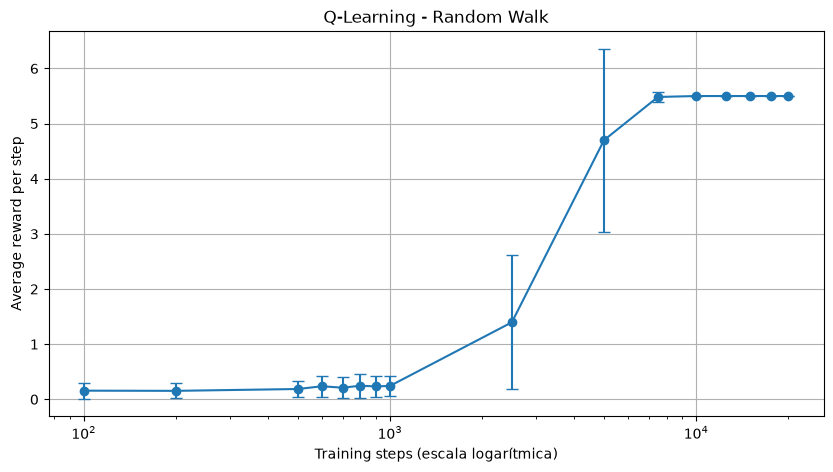

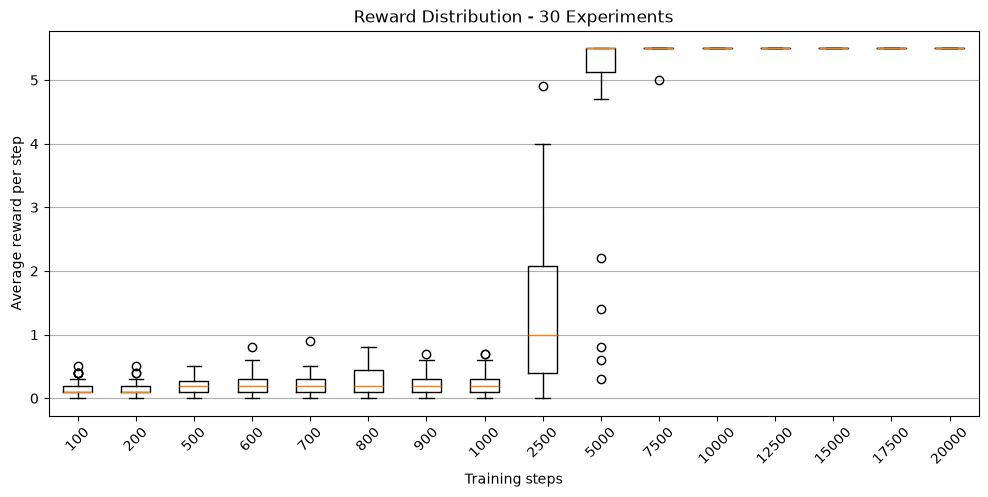

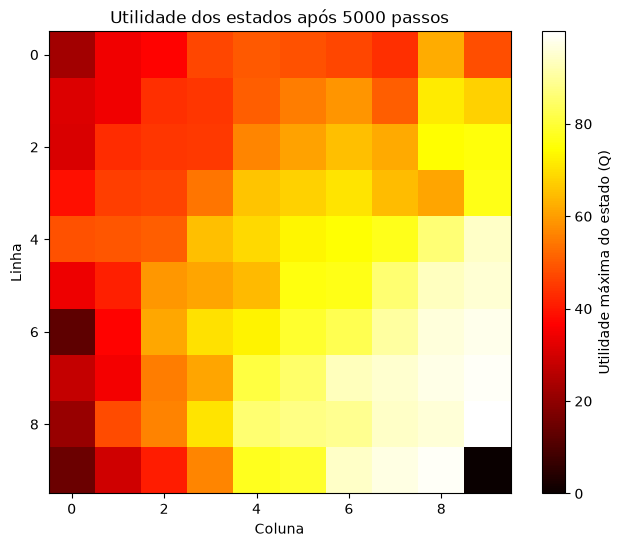

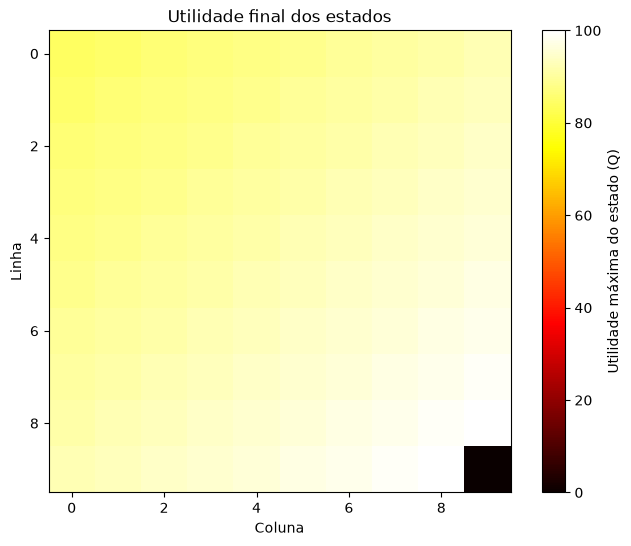

Coluna,1,2,3,4,5,6,7,8,9,10
Linha,,,,,,,,,,
1,right,right,down,down,right,down,down,down,down,down
2,right,right,right,right,right,down,right,down,down,down
3,right,right,right,right,down,down,right,down,down,down
4,right,right,right,right,right,right,down,right,down,down
5,right,down,right,right,right,right,right,right,down,down
6,right,right,right,right,right,right,down,down,down,down
7,right,down,right,right,right,right,down,right,down,down
8,right,right,right,right,right,right,right,right,right,down
9,down,right,right,right,down,right,right,right,right,down


In [57]:
results = run_experiments()

rewards, times = analyze_results(results)

plot_rewards(rewards)
plot_boxplots(rewards)
plot_heatmap_checkpoint(results, seed=10, test_point=5000)
plot_heatmap(results, seed=10) # Heatmap da utilidade final (20 000 passos)
plot_policy_dataframe(results[10]["Q"]) # Mapa da politica aprendida ( 20 000 passos))


**Resultados e Observações - Q-learning com random walk**

- **Evolução da aprendizagem:** até 1000 passos de treino a recompensa média por passo é baixa, dado que Q tem poucos valores diferentes de zero e a política testada é quase aleatória. Entre 2500 e 7500 passos a recompensa sobe de forma acentuada, com grande variabilidade entre experiências. A partir de 10 000 passos todas as experiências estabilizam. 
- **Comparação com o baseline:** o agente que usa Q obtém aproximadamente 5,5 por passo, face a 0,31 do agente aleatório do Exercício 1. 
- **Mapas de utilidade:** após 5000 passos o valor ainda não chegou a algumas zonas afastadas do objetivo (zonas escuras). No final, a utilidade diminui de forma regular com a distância ao estado 100, e o estado 100 tem utilidade 0 por ser terminal.
- **Melhor ação por estado:** a tabela de política só contém `down` e `right`, as ações que aproximam o robô do estado 100. Em muitos estados as duas são igualmente boas, porque há vários caminhos de igual comprimento.

### Alínea b - Q-learning com greedy policy

Mean execution time: 0.472411 s
Std execution time: 0.082736 s


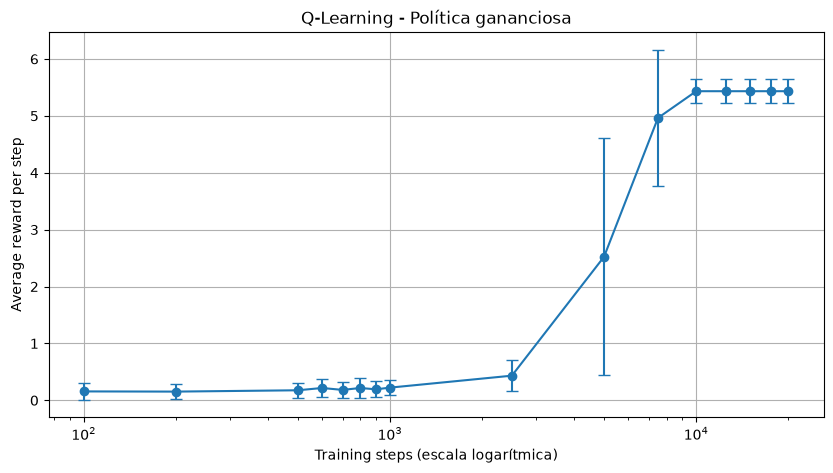

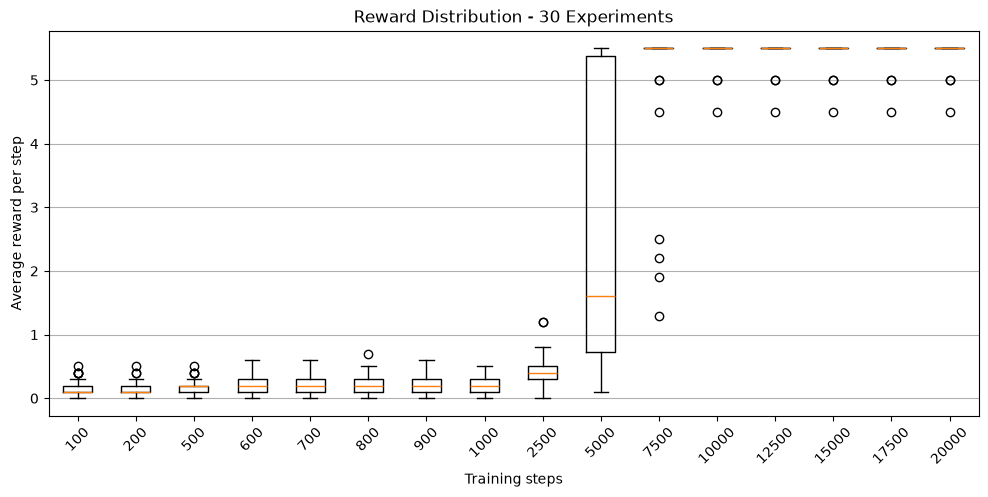

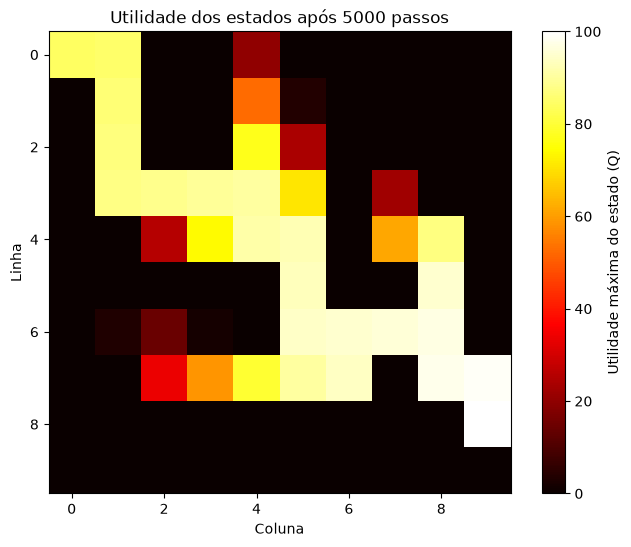

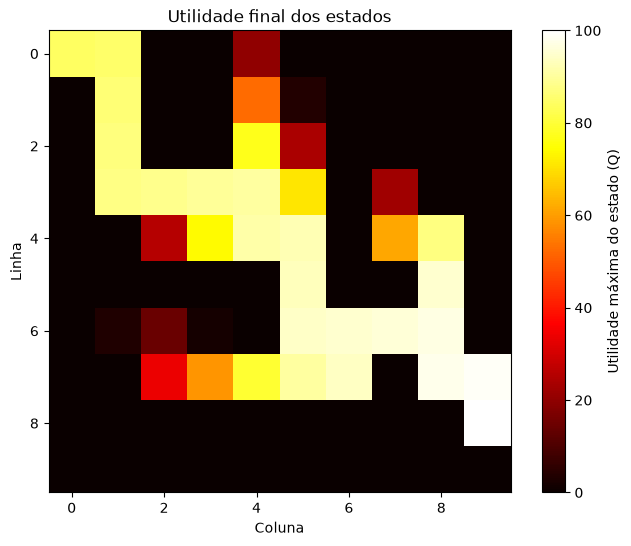

Coluna,1,2,3,4,5,6,7,8,9,10
Linha,,,,,,,,,,
1,right,down,·,·,down,·,·,·,·,·
2,·,down,·,·,down,left,·,·,·,·
3,·,down,·,·,down,down,·,·,·,·
4,·,right,right,right,down,down,·,down,·,·
5,·,·,right,right,right,down,·,right,down,·
6,·,·,·,·,·,down,·,·,down,·
7,·,right,down,down,·,right,right,right,down,·
8,·,·,right,right,right,right,up,·,right,down
9,·,·,·,·,·,·,·,·,·,down


In [58]:
results_b = run_experiments(train_policy=best_action)

rewards_b, times_b = analyze_results(results_b)

plot_rewards(rewards_b, title="Q-Learning - Política gananciosa")
plot_boxplots(rewards_b)
plot_heatmap_checkpoint(results_b, seed=10, test_point=5000)
plot_heatmap(results_b, seed=10)
plot_policy_dataframe(results_b[10]["Q"])

**Resultados e Observações - Q-learning com greedy policy**

- **Evolução da aprendizagem:** a recompensa média por passo mantém-se baixa até cerca de 2500 passos de treino e sobe de forma acentuada entre 5000 e 7500, com grande variabilidade entre experiências (barras de erro e caixa do boxplot muito largas aos 5000 passos). 
- **Comparação com o baseline:** a convergência é mais lenta e menos fiável que o random walk.Face ao baseline do Exercício 1 (0,31), a melhoria continua a ser muito grande.
- **Mapas de utilidade:** apenas uma parte dos estados tem utilidade positiva (zonas pretas nos mapas), pois a política gananciosa só atualiza os estados que visita, isto é, os do caminho que segue. Os mapas aos 5000 passos e final são muito semelhantes, porque o caminho já estava definido.
- **Melhor ação por estado:** a tabela de política só é fiável nos estados aprendidos. Nos restantes, assinalados com "·", Q é nula e não existe ação preferida.


## Exercício 3 

A função `greedy_policy` recebe o parâmetro `greed` e devolve uma política de treino com **greed fixo**. A política resultante escolhe, com probabilidade `greed`, a melhor ação segundo Q e, com probabilidade 1 - `greed`, uma ação aleatória.

A função `greed_schedule` define o valor do greed em função do passo de treino. O greed mantém-se em 0,3 durante os primeiros 30% do treino (6000 passos) e aumenta linearmente a partir daí, atingindo 1,0 no último passo (20 000). Assim, o agente realiza mais **exploration**, quando Q ainda tem pouca informação, e passa a aproveitar progressivamente o que aprendeu (**exploitation**).

A função `scheduled_greed_policy` define uma política de treino com **greed crescente**. Em cada passo, calcula o greed correspondente através de `greed_schedule` e escolhe a melhor ação segundo Q com essa probabilidade, ou uma ação aleatória no caso contrário. 

In [59]:
def greedy_policy(greed):
    def policy(Q, s, rng, step=None):
        if rng.random() < greed:
            return best_action(Q, s, rng)
        return random_action(rng)
    return policy

def greed_schedule(step, n_steps=N_TRAIN_STEPS, start=0.3, hold=0.3):
    hold_steps = hold * n_steps # numero de passos em que o greed é mantido constante
    if step <= hold_steps:
        return start
    return start + (1 - start) * (step - hold_steps) / (n_steps - hold_steps)

def scheduled_greed_policy(Q, s, rng, step=None):
    if rng.random() < greed_schedule(step):
        return best_action(Q, s, rng)
    return random_action(rng)

In [60]:
GREED_VALUES = [0.2, 0.5, 0.9]

results_greed = {
    g: run_experiments(train_policy=greedy_policy(g))
    for g in GREED_VALUES
}

results_schedule = run_experiments(train_policy=scheduled_greed_policy)

all_results = {
    **{f"Greed = {g}": results_greed[g] for g in GREED_VALUES},
    "Greed crescente": results_schedule
}

all_rewards = {
    nome: np.array([r["test_rewards"] for r in res])
    for nome, res in all_results.items()
}

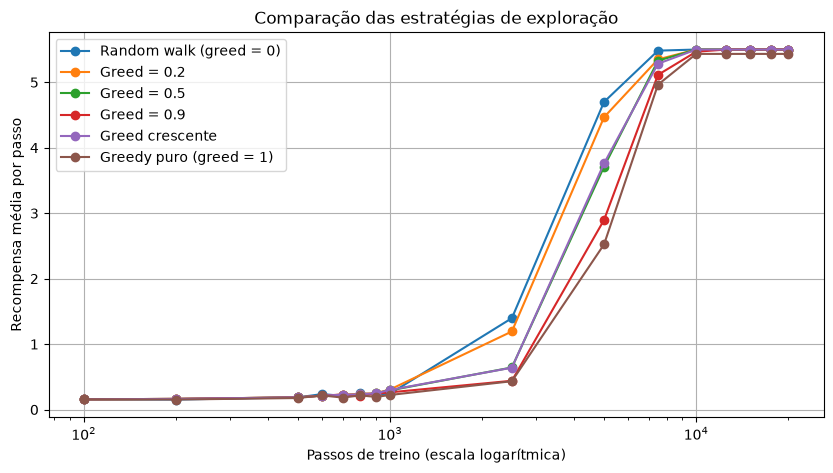

,2500 passos,5000 passos,7500 passos,20000 passos
Random walk (greed = 0),1.397 ± 1.217,4.700 ± 1.661,5.483 ± 0.090,5.500 ± 0.000
Greed = 0.2,1.193 ± 1.440,4.467 ± 1.777,5.350 ± 0.808,5.500 ± 0.000
Greed = 0.5,0.643 ± 0.532,3.710 ± 2.141,5.330 ± 0.642,5.500 ± 0.000
Greed = 0.9,0.440 ± 0.209,2.897 ± 2.203,5.113 ± 1.106,5.500 ± 0.000
Greed crescente,0.640 ± 0.463,3.760 ± 2.084,5.283 ± 0.812,5.500 ± 0.000
Greedy puro (greed = 1),0.433 ± 0.271,2.523 ± 2.082,4.963 ± 1.202,5.433 ± 0.213


In [61]:
def plot_comparison(all_rewards):
    plt.figure(figsize=(10, 5))

    for nome, rewards in all_rewards.items():
        mean = rewards.mean(axis=0)
        plt.plot(TEST_POINTS, mean, marker="o", label=nome)

    plt.xscale("log")
    plt.xlabel("Passos de treino (escala logarítmica)")
    plt.ylabel("Recompensa média por passo")
    plt.title("Comparação das estratégias de exploração")
    plt.grid()
    plt.legend()
    plt.show()

def comparison_table(all_rewards, points=(2500, 5000, 7500, 20000)):
    linhas = {}
    for nome, r in all_rewards.items():
        linha = {}
        for p in points:
            j = TEST_POINTS.index(p)
            linha[f"{p} passos"] = f"{r[:, j].mean():.3f} ± {r[:, j].std():.3f}"
        linhas[nome] = linha
    return pd.DataFrame(linhas).T

all = {
    "Random walk (greed = 0)": rewards,
    **all_rewards,
    "Greedy puro (greed = 1)": rewards_b
}

plot_comparison(all)
display(comparison_table(all))

In [62]:
all_results = {"Random walk": results, **all_results, "Greedy puro": results_b}

for nome, res in all_results.items():
    n = np.mean([(r["Q"].max(axis=1) == 0).sum() for r in res])
    print(f"{nome}: {n:.1f} estados sem valor aprendido (média)")

Random walk: 1.0 estados sem valor aprendido (média)
Greed = 0.2: 1.1 estados sem valor aprendido (média)
Greed = 0.5: 10.5 estados sem valor aprendido (média)
Greed = 0.9: 35.5 estados sem valor aprendido (média)
Greed crescente: 8.6 estados sem valor aprendido (média)
Greedy puro: 60.3 estados sem valor aprendido (média)


In [63]:
print("Random walk (sem greed)")
plot_policy_dataframe(results[10]["Q"])

print("Greed = 0.5")
plot_policy_dataframe(results_greed[0.5][10]["Q"])

print("Greed crescente")
plot_policy_dataframe(results_schedule[10]["Q"])

Random walk (sem greed)


Coluna,1,2,3,4,5,6,7,8,9,10
Linha,,,,,,,,,,
1,right,right,down,down,right,down,down,down,down,down
2,right,right,right,right,right,down,right,down,down,down
3,right,right,right,right,down,down,right,down,down,down
4,right,right,right,right,right,right,down,right,down,down
5,right,down,right,right,right,right,right,right,down,down
6,right,right,right,right,right,right,down,down,down,down
7,right,down,right,right,right,right,down,right,down,down
8,right,right,right,right,right,right,right,right,right,down
9,down,right,right,right,down,right,right,right,right,down


Greed = 0.5


Coluna,1,2,3,4,5,6,7,8,9,10
Linha,,,,,,,,,,
1,down,down,down,down,down,left,left,·,·,·
2,right,down,down,down,down,down,left,·,down,·
3,right,right,down,down,down,down,left,down,left,down
4,right,right,right,down,down,down,down,down,left,left
5,up,right,right,down,down,down,down,down,up,left
6,down,down,down,down,down,down,down,down,right,down
7,right,right,right,right,down,down,down,down,right,down
8,up,up,up,right,right,down,down,down,right,down
9,·,up,right,right,right,right,right,down,down,down


Greed crescente


Coluna,1,2,3,4,5,6,7,8,9,10
Linha,,,,,,,,,,
1,down,down,right,down,right,down,right,down,left,down
2,right,down,down,down,down,down,down,left,down,down
3,right,right,right,down,down,down,down,down,down,down
4,right,right,right,down,down,down,down,down,right,down
5,up,up,right,right,down,down,down,down,down,down
6,up,up,right,right,right,right,right,right,down,down
7,·,right,right,up,up,right,right,right,down,down
8,·,·,down,down,right,right,down,right,down,down
9,·,·,right,right,down,down,down,down,right,down


**Resultados e Observações - Greed fixo e greed crescente**

- **Efeito do greed fixo:** quanto maior o greed, mais lenta é a aprendizagem. Aos 5000 passos a recompensa média desce de 4,47 (greed 0,2) para 3,71 (0,5) e 2,90 (0,9), e a variabilidade entre experiências aumenta. 
- **Greed crescente:** tem um comportamento semelhante ao greed 0,5 (3,76 aos 5000 passos) e não supera o random walk (4,70). Nas 30 experiências chega a 5,5 no fim do treino.
- **Estados aprendidos:** quanto maior o greed, mais estados ficam com Q nulo no fim (em média 1 no random walk, 10,5 com greed 0,5, 35,5 com greed 0,9 e 60,3 no greedy puro). Isto vê-se nos mapas de utilidade e nas tabelas de política, nas células marcadas com "·".
- **Valor final:** aos 20 000 passos todas as variantes, exceto o greedy puro, chegam a 5,5 com desvio-padrão nulo, ou seja, todas as experiências convergem para a política ótima. O greedy puro fica em 5,43 com desvio-padrão 0,21, porque a ausência de exploração pode fixar um caminho mais longo em algumas experiências. Misturar exploração com exploitation evita este problema.
- **Conclusão:** neste ambiente (grelha pequena, sem paredes, recompensa só no objetivo) explorar é barato, por isso o random walk aprende mais depressa e o greed não traz vantagem. Um greed alto só se justifica quando explorar é caro, o que acontece em ambientes maiores ou com penalizações. O greed crescente é um compromisso: aprende mais devagar do que o random walk, mas não fica preso a caminhos sub-ótimos como o greedy puro.

## Exercício 4 - Ambiente com paredes

Neste exercício mantemos o Q-learning e o protocolo experimental dos exercícios anteriores e acrescentamos as paredes da Figura 4. As células azuis interiores correspondem às colunas 4 (linhas 1 a 9) e 7 (linhas 2 a 10); a moldura exterior é representada por uma faixa de paredes fora das casas numeradas, sem bloquear os estados 1 a 100. Ao tentar entrar numa parede ou sair da grelha, o robô permanece no mesmo estado e recebe uma penalização de `-0.1`. O estado 100 continua a dar uma recompensa de 100.

Executamos 30 experiências e avaliamos nos mesmos pontos de treino. As curvas e os boxplots mostram a evolução da recompensa; os mapas de valores Q e de política permitem verificar se o agente aprendeu a contornar as paredes.


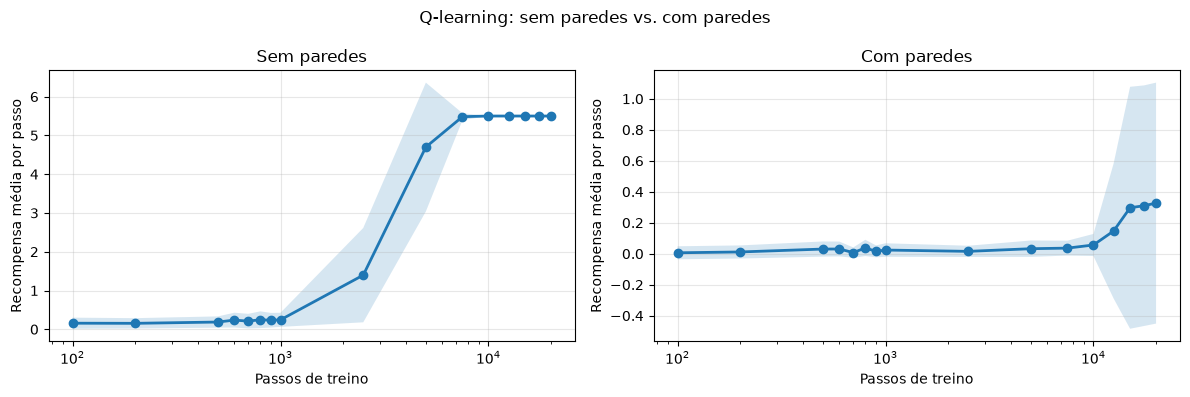

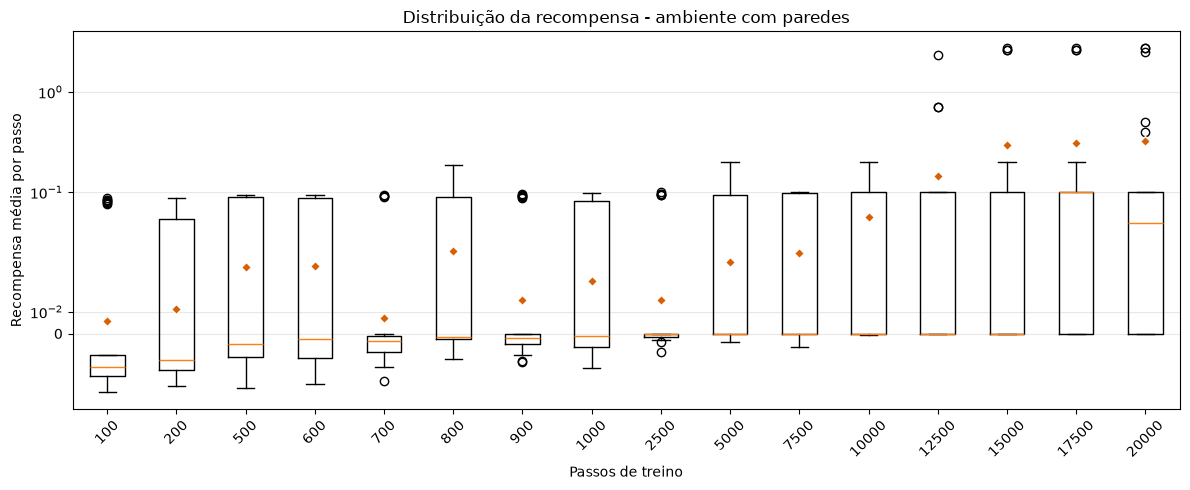

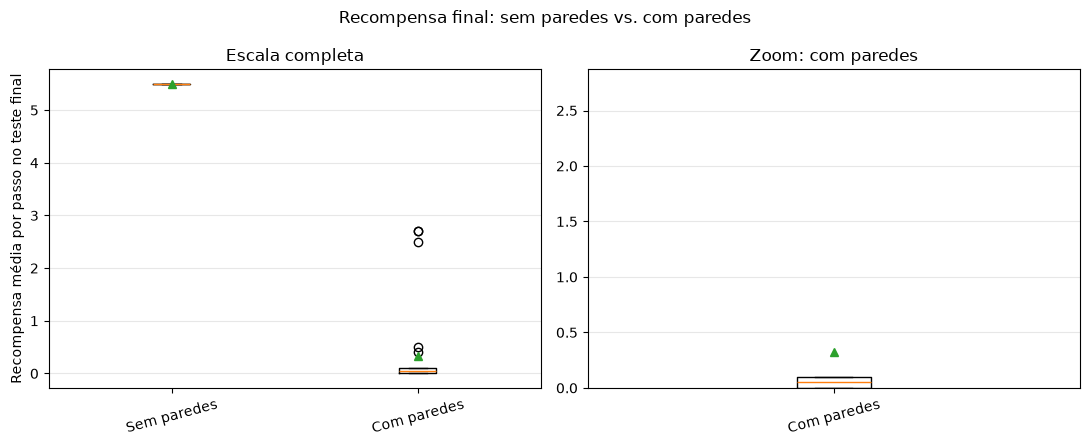

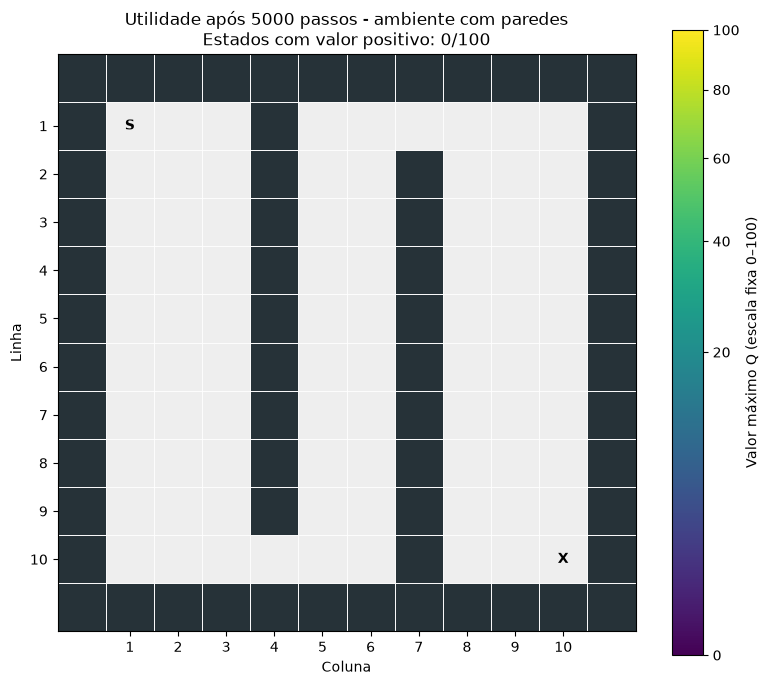

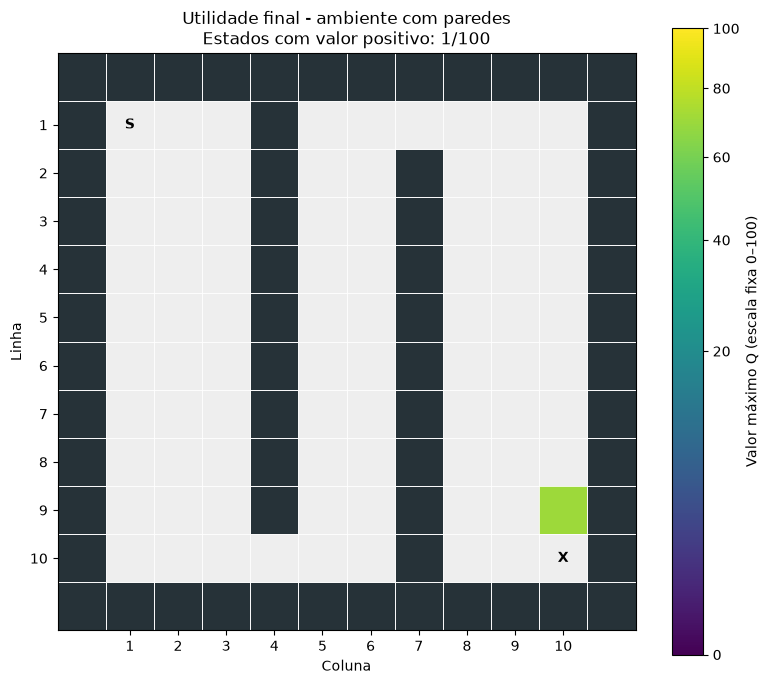

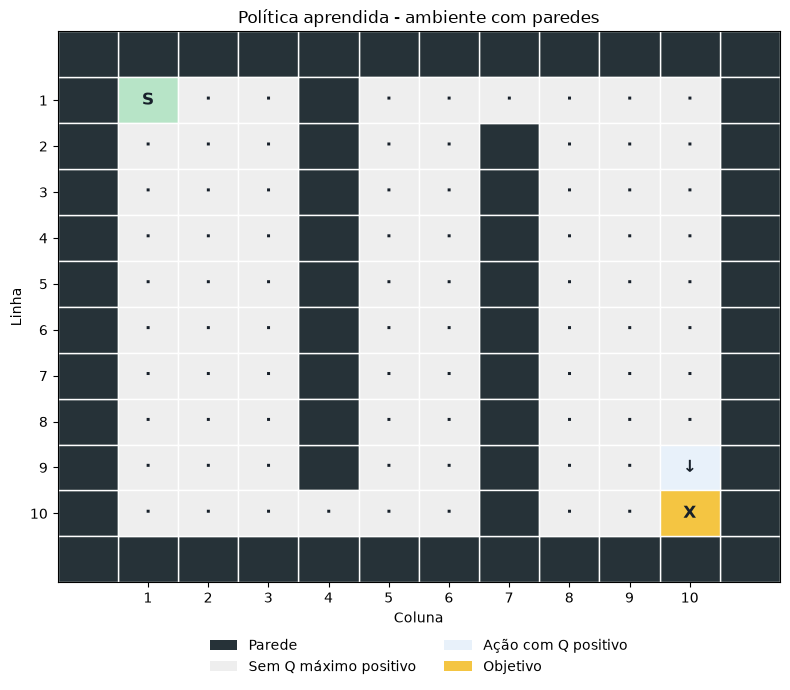

Recompensa final sem paredes: 5.500 +/- 0.000
Recompensa final com paredes: 0.327 +/- 0.778
Tempo médio com paredes: 0.2333 s


In [64]:
# Exercício 4: ambiente com paredes e penalização por colisão
INTERNAL_WALLS = ({(row, 4) for row in range(1, 10)} |
                  {(row, 7) for row in range(2, 11)})
OUTER_WALLS = ({(0, col) for col in range(12)} | {(11, col) for col in range(12)} |
               {(row, 0) for row in range(12)} | {(row, 11) for row in range(12)})
WALLS = INTERNAL_WALLS | OUTER_WALLS
WALL_PENALTY = -0.1


def state_to_position(s):
    return (s - 1) // 10 + 1, (s - 1) % 10 + 1


def position_to_state(row, col):
    return (row - 1) * 10 + col


def valid_neighbors(s):
    row, col = state_to_position(s)
    candidates = [(row - 1, col), (row + 1, col),
                  (row, col - 1), (row, col + 1)]
    return [position_to_state(r, c) for r, c in candidates
            if 1 <= r <= 10 and 1 <= c <= 10 and (r, c) not in WALLS]


def transition_walls(s, a, rng=None, stochastic_prob=0.0):
    # With noise, replace the chosen move by a uniformly random direction.
    # The normal wall/boundary rule below still applies to that direction.
    if rng is not None and stochastic_prob > 0 and rng.random() < stochastic_prob:
        a = random_action(rng)

    row, col = state_to_position(s)
    deltas = {'up': (-1, 0), 'down': (1, 0),
              'left': (0, -1), 'right': (0, 1)}
    dr, dc = deltas[a]
    target = (row + dr, col + dc)
    if not (1 <= target[0] <= 10 and 1 <= target[1] <= 10) or target in WALLS:
        return s, True
    return position_to_state(*target), False


def reward_walls(s_next, hit_wall):
    if hit_wall:
        return WALL_PENALTY
    return reward(s_next)


def best_action_walls(Q, s, rng):
    q = Q[s - 1]
    return ACTIONS[rng.choice(np.flatnonzero(q == q.max()))]


def random_policy_walls(Q, s, rng, step=None):
    return random_action(rng)


def run_q_learning_walls(seed, train_policy=random_policy_walls,
                         stochastic_prob=0.0):
    rng_train = np.random.default_rng(seed * 2 + 1)
    rng_test = np.random.default_rng(seed * 2 + 2)
    Q = np.zeros((N_STATES, len(ACTIONS)))
    s = INITIAL_STATE
    episode_steps = 0
    test_rewards = []
    q_snapshots = {}
    start_time = time.perf_counter()

    for step in range(1, N_TRAIN_STEPS + 1):
        a = train_policy(Q, s, rng_train, step)
        s_next, hit_wall = transition_walls(s, a, rng_train, stochastic_prob)
        action_index = ACTIONS.index(a)
        target = reward_walls(s_next, hit_wall) + GAMMA * Q[s_next - 1].max()
        Q[s - 1, action_index] = (1 - ALPHA) * Q[s - 1, action_index] + ALPHA * target
        episode_steps += 1

        if s_next == GOAL_STATE or episode_steps == MAX_STEPS:
            s_next = INITIAL_STATE
            episode_steps = 0
        s = s_next

        if step in TEST_POINTS:
            test_rewards.append(test_policy_walls(Q, rng_test, stochastic_prob))
            q_snapshots[step] = Q.copy()

    return {'test_rewards': test_rewards,
            'execution_time': time.perf_counter() - start_time,
            'Q': Q, 'q_snapshots': q_snapshots}


def test_policy_walls(Q, rng, stochastic_prob=0.0):
    s = INITIAL_STATE
    total_reward = 0.0
    episode_steps = 0
    for _ in range(TEST_STEPS):
        a = best_action_walls(Q, s, rng)
        s_next, hit_wall = transition_walls(s, a, rng, stochastic_prob)
        total_reward += reward_walls(s_next, hit_wall)
        episode_steps += 1
        if s_next == GOAL_STATE or episode_steps == MAX_STEPS:
            s_next = INITIAL_STATE
            episode_steps = 0
        s = s_next
    return total_reward / TEST_STEPS


def run_experiments_walls(train_policy=random_policy_walls, stochastic_prob=0.0):
    return [run_q_learning_walls(seed, train_policy, stochastic_prob)
            for seed in range(30)]


def rewards_array(results):
    return np.array([result['test_rewards'] for result in results])


def plot_wall_learning(comparisons, title):
    # Painel separado por condição evita comprimir resultados baixos junto do baseline.
    fig, axes = plt.subplots(1, len(comparisons), figsize=(6*len(comparisons), 4), squeeze=False)
    for ax, (name, values) in zip(axes[0], comparisons.items()):
        mean, std = values.mean(axis=0), values.std(axis=0)
        ax.plot(TEST_POINTS, mean, marker='o', linewidth=2)
        ax.fill_between(TEST_POINTS, mean-std, mean+std, alpha=0.18)
        ax.set_xscale('log'); ax.set_xlabel('Passos de treino')
        ax.set_ylabel('Recompensa média por passo'); ax.set_title(name)
        ax.grid(True, alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); plt.show()

def plot_checkpoint_boxplots(values, title):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.boxplot(values, tick_labels=TEST_POINTS, showmeans=True,
        meanprops={'marker':'D','markerfacecolor':'#d95f02','markeredgecolor':'white','markersize':5})
    ax.set_xlabel('Passos de treino'); ax.set_ylabel('Recompensa média por passo')
    ax.set_title(title); ax.set_yscale('symlog', linthresh=0.05)
    ax.tick_params(axis='x', rotation=45); ax.grid(axis='y', alpha=0.3)
    fig.tight_layout(); plt.show()

def plot_final_comparison(comparisons, title):
    names=list(comparisons); data=[v[:,-1] for v in comparisons.values()]
    fig,(ax,zoom)=plt.subplots(1,2,figsize=(11,4.5))
    ax.boxplot(data,tick_labels=names,showmeans=True); ax.set_ylabel('Recompensa média por passo no teste final')
    ax.set_title('Escala completa'); ax.tick_params(axis='x',rotation=15); ax.grid(axis='y',alpha=0.3)
    # When comparing against the wall-free baseline, zoom only the wall condition.
    if len(data)==2 and 'sem paredes' in names[0].lower() and 'com paredes' in names[1].lower():
        zoom_data, zoom_names = [data[1]], [names[1]]
        zoom_title = 'Zoom: com paredes'
    else:
        zoom_data, zoom_names = data, names
        zoom_title = 'Distribuição central (sem extremos)'
    zoom.boxplot(zoom_data,tick_labels=zoom_names,showmeans=True,showfliers=False)
    hi=max(0.1,float(max(np.percentile(v,95) for v in zoom_data)))
    lo=min(0.0,float(min(v.min() for v in zoom_data)))
    zoom.set_ylim(lo,hi*1.1)
    zoom.set_title(zoom_title); zoom.tick_params(axis='x',rotation=15); zoom.grid(axis='y',alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); plt.show()

def plot_wall_heatmap(result, test_point, title):
    from matplotlib.colors import PowerNorm
    Q=result['q_snapshots'][test_point]
    utilities=Q.max(axis=1).reshape(10,10).astype(float)
    utilities[utilities==0]=np.nan  # células sem valor positivo ficam cinzentas
    padded=np.full((12,12),np.nan)
    padded[1:11,1:11]=utilities
    cmap=plt.cm.viridis.copy(); cmap.set_bad(color='#eeeeee')
    fig,ax=plt.subplots(figsize=(8,7))
    im=ax.imshow(padded,cmap=cmap,norm=PowerNorm(gamma=0.45,vmin=0,vmax=100))
    for row,col in WALLS:
        ax.add_patch(plt.Rectangle((col-.5,row-.5),1,1,facecolor='#263238',edgecolor='white',linewidth=0.5))
    ax.text(1,1,'S',ha='center',va='center',color='black',weight='bold')
    ax.text(10,10,'X',ha='center',va='center',color='black',weight='bold')
    ax.set_xlim(-0.5,11.5); ax.set_ylim(11.5,-0.5)
    ax.set_xticks(range(1,11),range(1,11)); ax.set_yticks(range(1,11),range(1,11))
    ax.set_xlabel('Coluna'); ax.set_ylabel('Linha')
    ax.set_title(title+f'\nEstados com valor positivo: {int(np.isfinite(utilities).sum())}/100')
    ax.set_xticks(np.arange(-0.5,12,1),minor=True); ax.set_yticks(np.arange(-0.5,12,1),minor=True)
    ax.grid(which='minor',color='white',linewidth=0.6); ax.tick_params(which='minor',bottom=False,left=False)
    fig.colorbar(im,ax=ax,label='Valor máximo Q (escala fixa 0–100)')
    fig.tight_layout(); plt.show()
def plot_wall_policy(Q, title):
    fig,ax=plt.subplots(figsize=(8,7)); ax.set_xlim(-0.5,11.5); ax.set_ylim(11.5,-0.5)
    ax.set_xticks(range(1,11),range(1,11)); ax.set_yticks(range(1,11),range(1,11))
    arrows={'up':'↑','down':'↓','left':'←','right':'→'}
    for row,col in WALLS:
        ax.add_patch(plt.Rectangle((col-.5,row-.5),1,1,facecolor='#263238',edgecolor='white',linewidth=1))
    for s in range(1,101):
        row,col=state_to_position(s)
        if (row,col) in INTERNAL_WALLS: continue
        if s==GOAL_STATE: color,label='#f4c542','X'
        elif Q[s-1].max()>0: color,label='#e8f1fa',arrows[ACTIONS[int(Q[s-1].argmax())]]
        elif s==INITIAL_STATE: color,label='#b7e4c7','S'
        else: color,label='#eeeeee','·'
        ax.add_patch(plt.Rectangle((col-.5,row-.5),1,1,facecolor=color,edgecolor='white',linewidth=1))
        ax.text(col,row,label,ha='center',va='center',color='#17202a',fontsize=12,weight='bold')
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor='#263238',label='Parede'), Patch(facecolor='#eeeeee',label='Sem Q máximo positivo'), Patch(facecolor='#e8f1fa',label='Ação com Q positivo'), Patch(facecolor='#f4c542',label='Objetivo')], loc='upper center', bbox_to_anchor=(0.5,-0.08), ncol=2, frameon=False)
    ax.set_title(title); ax.set_xlabel('Coluna'); ax.set_ylabel('Linha')
    fig.tight_layout(); plt.show()


results_walls = run_experiments_walls()
rewards_walls = rewards_array(results_walls)
plot_wall_learning({'Sem paredes': rewards, 'Com paredes': rewards_walls},
                   'Q-learning: sem paredes vs. com paredes')
plot_checkpoint_boxplots(rewards_walls,
                         'Distribuição da recompensa - ambiente com paredes')
plot_final_comparison({'Sem paredes': rewards, 'Com paredes': rewards_walls},
                      'Recompensa final: sem paredes vs. com paredes')
plot_wall_heatmap(results_walls[10], 5000,
                  'Utilidade após 5000 passos - ambiente com paredes')
plot_wall_heatmap(results_walls[10], 20000,
                  'Utilidade final - ambiente com paredes')
plot_wall_policy(results_walls[10]['Q'],
                 'Política aprendida - ambiente com paredes')
print(f'Recompensa final sem paredes: {rewards[:, -1].mean():.3f} +/- {rewards[:, -1].std():.3f}')
print(f'Recompensa final com paredes: {rewards_walls[:, -1].mean():.3f} +/- {rewards_walls[:, -1].std():.3f}')
print(f'Tempo médio com paredes: {np.mean([r["execution_time"] for r in results_walls]):.4f} s')


**Resultados e observações.** No ponto final, a recompensa média guardada é `0.567 ± 1.027`, bastante abaixo dos `5.500 ± 0.000` obtidos sem paredes. O ambiente exige que o robô contorne a primeira barreira pela linha 10, suba até à abertura da linha 1 na segunda barreira e depois siga para o objetivo. A recompensa final indica que, com 20 000 passos e a política de treino aleatória, a aprendizagem não foi fiável em todas as experiências. Na experiência da seed 10, só 3 estados têm valor Q máximo positivo; no estado inicial, Q é `[-0.1, 0, -0.1, 0]`, pelo que ainda não há uma ação preferida aprendida para começar o percurso. No mapa de política, os pontos significam “Q máximo não positivo”; não provam que o estado nunca foi visitado. Deve interpretar-se a curva e os boxplots em conjunto com o mapa da política: um valor baixo pode refletir experiências que ainda não aprenderam este percurso.


## Exercício 5 - Transições estocásticas

Partimos do ambiente com paredes do Exercício 4. Em cada passo, com probabilidade de 5%, a direção escolhida é substituída por uma das quatro direções possíveis, escolhida uniformemente. Nos restantes 95% dos casos, usa-se a direção indicada pela política. Se a direção executada levar a uma parede ou para fora da grelha, o robô permanece no mesmo estado e recebe a penalização de `-0.1`, tal como no Exercício 4.

Usamos 30 experiências e os mesmos pontos de avaliação. Comparamos as curvas, os boxplots, os heatmaps e as políticas com o ambiente determinístico.


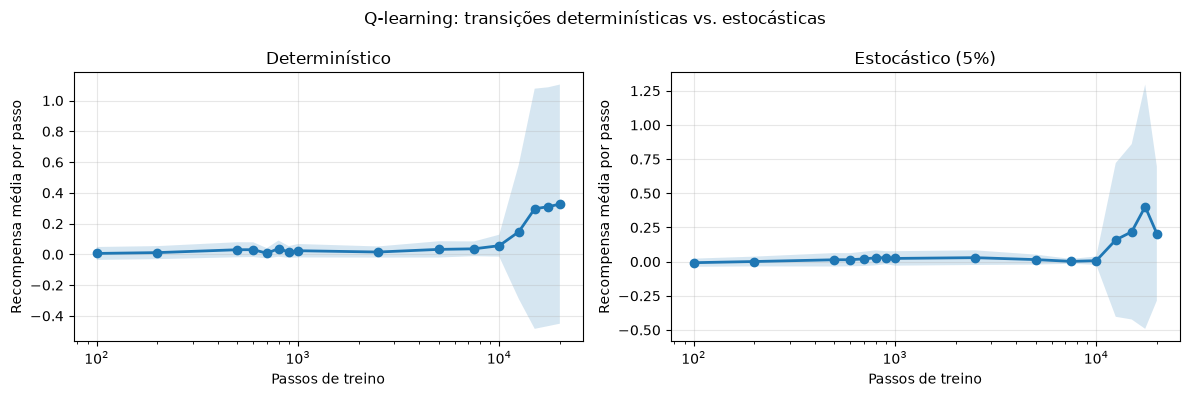

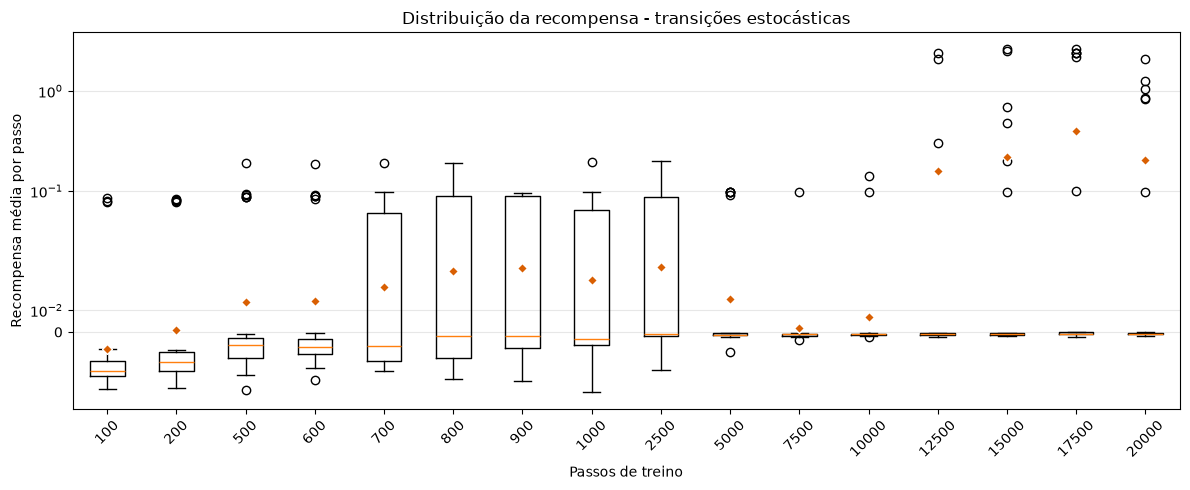

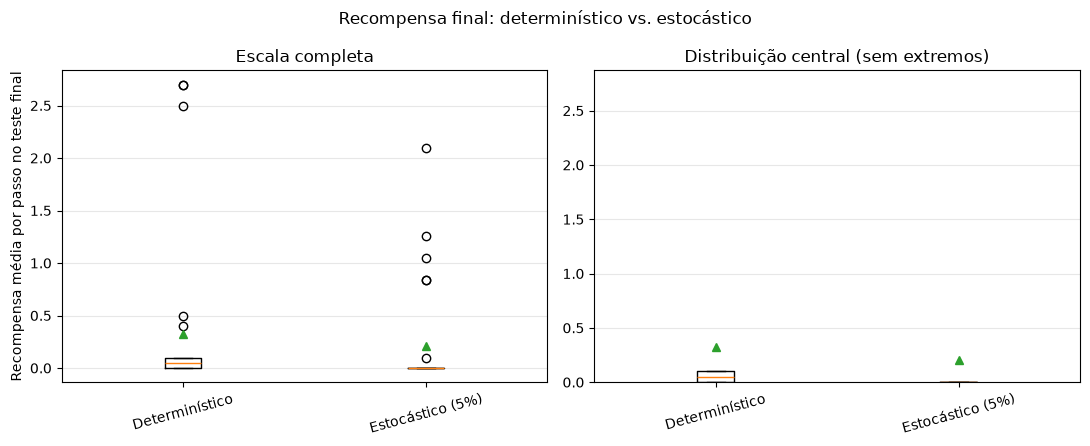

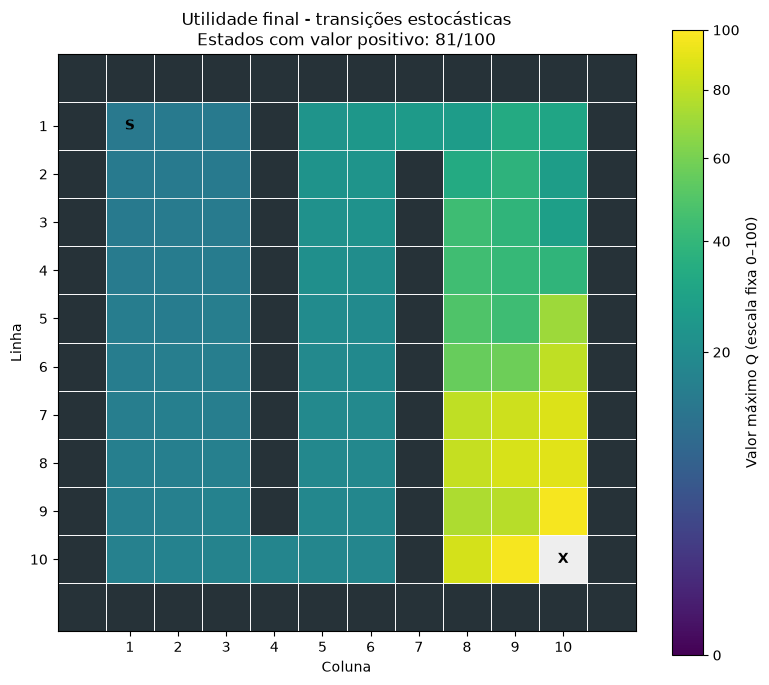

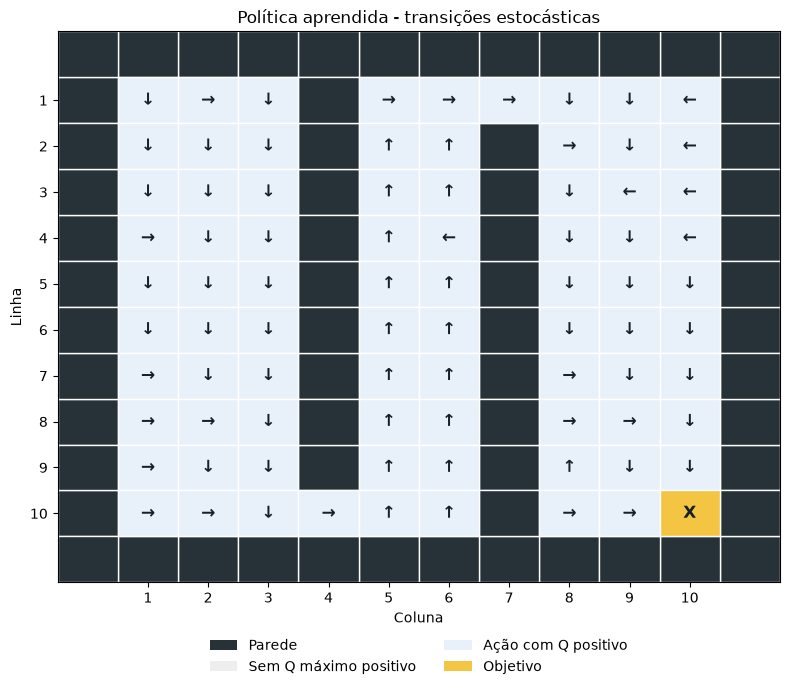

Recompensa final determinística: 0.327 +/- 0.778
Recompensa final estocástica: 0.205 +/- 0.491
Variação da recompensa final: -0.121


In [65]:
# Exercício 5: transições estocásticas com probabilidade de 5%
STOCHASTIC_PROB = 0.05
results_stochastic = run_experiments_walls(stochastic_prob=STOCHASTIC_PROB)
rewards_stochastic = rewards_array(results_stochastic)

plot_wall_learning({'Determinístico': rewards_walls,
                    'Estocástico (5%)': rewards_stochastic},
                   'Q-learning: transições determinísticas vs. estocásticas')
plot_checkpoint_boxplots(rewards_stochastic,
                         'Distribuição da recompensa - transições estocásticas')
plot_final_comparison({'Determinístico': rewards_walls,
                       'Estocástico (5%)': rewards_stochastic},
                      'Recompensa final: determinístico vs. estocástico')
plot_wall_heatmap(results_stochastic[10], 20000,
                  'Utilidade final - transições estocásticas')
plot_wall_policy(results_stochastic[10]['Q'],
                 'Política aprendida - transições estocásticas')
print(f'Recompensa final determinística: {rewards_walls[:, -1].mean():.3f} +/- {rewards_walls[:, -1].std():.3f}')
print(f'Recompensa final estocástica: {rewards_stochastic[:, -1].mean():.3f} +/- {rewards_stochastic[:, -1].std():.3f}')
print(f'Variação da recompensa final: {rewards_stochastic[:, -1].mean() - rewards_walls[:, -1].mean():+.3f}')


**Resultados e observações.** Com ruído de 5%, o resultado final foi 0.205 ± 0.491, comparado com 0.327 ± 0.778 no ambiente determinístico (diferença das médias: -0.121). A transição aleatória também pode causar colisões, que contam com a penalização de `-0.1`. A direção e a dimensão do efeito devem ser interpretadas com as curvas e os boxplots das 30 experiências.

## Exercício 6 - Representação do estado através de sonar

Sem estados numerados, o robô pode usar as leituras dos sonares como observação. Uma representação possível é um vetor de quatro distâncias relativas à orientação atual do robô.


In [66]:
# Exercício 6: exemplo de vetor de estado baseado em sonar

def sonar_state_vector(distances):
    """Representa as distâncias às paredes nas quatro direções relativas."""
    required = ('front', 'right', 'back', 'left')
    if set(distances) != set(required):
        raise ValueError(f'As distâncias devem conter exatamente {required}.')
    values = np.array([distances[name] for name in required], dtype=float)
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError('As distâncias devem ser valores finitos e não negativos.')
    return values


example_state = sonar_state_vector({
    'front': 2.0,
    'right': 0.0,
    'back': 5.0,
    'left': 1.0,
})
print('Vetor [frente, direita, três, esquerda]:', example_state)
print('Número de componentes:', example_state.size)


Vetor [frente, direita, três, esquerda]: [2. 0. 5. 1.]
Número de componentes: 4


O vetor proposto é `[d_frente, d_direita, d_trás, d_esquerda]`. Cada valor indica o número de células livres até à primeira parede ou ao limite da grelha nessa direção, limitado ao alcance máximo do sensor. Por exemplo, `0` significa que existe uma parede imediatamente adjacente; se nenhuma parede for detetada dentro do alcance, pode usar-se o próprio valor máximo do sensor. O vetor deve ser recalculado após cada movimento.

As direções são relativas ao robô. Se as ações do agente forem absolutas (cima/baixo/esquerda/direita), também é necessário incluir a orientação atual para converter as leituras relativas em ações absolutas. O exemplo de código cria um vetor a partir de leituras fornecidas; não simula o sensor nem calcula as distâncias no mapa. A observação local pode ser ambígua: lugares diferentes podem gerar o mesmo vetor. Se isso impedir uma política adequada, pode acrescentar-se a orientação absoluta, guardar leituras e ações recentes ou usar uma memória interna.
